# How much spatial precision does the 100x100 input grid discard?

Every observation is drawn on a 100x100 grid before it enters the model. This notebook measures
what that costs on the two experimental datasets in the paper. The processed objects retain the
whole coordinate chain for every transcript: its raw position in microns, its position in native
camera pixels, and the 100x100 integer the model finally sees, so the cost can be measured
directly.

**For most cells the refit to 100x100 discards nothing.** Transcripts are placed first on an
integer grid the size of the cell itself (85x85 native pixels at the HEK median), and that grid
is then refit to 100x100. While a cell spans no more than 100 native pixels the refit is
injective: every native position keeps a grid pixel of its own, so the step is invertible and no
resolution is lost. That is the case for **57 % of HEK cells on both axes, and the median HEK
cell loses no positions on either** (§1). One grid pixel is then **0.18 um** against the
0.2125 um Xenium pixel, so the grid is the finer of the two.

**Where it does cost something, the cost is exact.** Above 100 px the fraction of native
positions that lose their own pixel is `1 - 100/extent`. 43 % of HEK cells have one axis past
that point, and in the ileum, whose enterocytes are both larger and markedly elongated, every
cell does: a median of 24 % of positions collapse across the cell and 54 % along it, with the
grid pixel reaching 0.24 um against a 0.108 um native pixel. The crop is resampled per axis, so
it is the long dimension of elongated cells that loses precision.

**The positional error it introduces is smaller than the camera's own.** Over all
**321,668,970** APEX transcripts, the refit moves a transcript a median of **0.047 um**, against
**0.053 um** for the rounding to native camera pixels that precedes it; even at the 99th
percentile it is 0.14 um, and the worst case anywhere is 0.32 um (§2). The step where sub-micron
precision is given up is the earlier one, onto the camera lattice.

**Where positions are lost, almost no transcript is affected.** A 100x100 frame holds 10,000
pixels for the few tens of transcripts in one observation, so it sits about 99.8 % empty. In the
HEK data **0.4 %** of transcripts share a pixel with another, and 95.6 % of observations have no
collision at all. In the ileum, where half the native positions along a cell's long axis
collapse, the figure is still only **1.1 %**, with 90 % of observations entirely conflict-free
(§2). Losing half of a lattice that was almost entirely unoccupied costs about one transcript in
a hundred, because the positions that disappear are overwhelmingly empty ones.

**Boundary crossing.** The median transcript sits **9 grid pixels, about 1.6 um, from the
nuclear boundary**. Only **6.7 %** lie within one pixel of it, which bounds the population that
a one-pixel error could reassign, and the displacement the grid actually introduces is 0.26 of a
pixel, roughly four times smaller than one pixel (§3).

**Scope.** These are the two experimental datasets in the paper. §1 is over every cell, §2 over
every transcript; §3 and the collision rates are over large random cell samples, stated per
panel. The cached tables are written by `scripts/input_resolution/measure_input_resolution.py`
from the published objects.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import paths
from palette import pattern_palette

WORK = paths.data("input_resolution")
FIG  = paths.figures("input_resolution")

# produced by scripts/input_resolution/measure_input_resolution.py, whose `cells` stage
# reproduces the stored subcell_row/subcell_col exactly from local_row/local_col and the
# native cell_bbox -- the gate that makes the error model below meaningful
DS = {"apex":  dict(label="APEX / HEK (Xenium)",  um_px=0.2125, colour="#1f77b4"),
      "ileum": dict(label="ileum (MERFISH)",      um_px=0.1080, colour="#d62728")}
GRID = 100
for k, v in DS.items():
    v["cells"] = pd.read_csv(WORK / f"cells_{k}.csv").dropna(subset=["bbox_h"])
    v["disp"]  = pd.read_csv(WORK / f"displacement_{k}.csv")
    v["occ"]   = pd.read_csv(WORK / f"occupancy_{k}.csv")
    v["bnd"]   = pd.read_csv(WORK / f"boundary_{k}.csv.gz")
    v["hist"]  = np.load(WORK / f"displacement_hist_{k}.npz")

COL = pattern_palette()
SURFACE, INK, INK_MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
mpl.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,
    "savefig.facecolor":SURFACE,"text.color":INK,"axes.labelcolor":INK_MUTED,
    "xtick.color":INK_MUTED,"ytick.color":INK_MUTED,"axes.edgecolor":GRIDC,
    "font.size":9,"axes.titlesize":10,"figure.dpi":120,
    "axes.spines.top":False,"axes.spines.right":False,"legend.frameon":False})

for k, v in DS.items():
    c = v["cells"]
    print(f"{v['label']:22s} {len(c):>7,} cells | "
          f"transcripts {int(v['hist']['n']):>12,} | "
          f"native pixel {v['um_px']:.4f} um")

APEX / HEK (Xenium)    154,296 cells | transcripts  321,668,970 | native pixel 0.2125 um
ileum (MERFISH)            408 cells | transcripts      179,286 | native pixel 0.1080 um


### How a cell becomes a 100x100 image

Three steps. A transcript is detected at a position in micrometres; it is rounded onto the
camera's own pixel grid; and the cell's bounding box — its own grid, whatever size that
happens to be — is then resampled to a fixed 100x100 frame. 

Below, one row of camera pixels and the image pixels they land on, for a typical cell of each
dataset. Filled circles are transcripts.

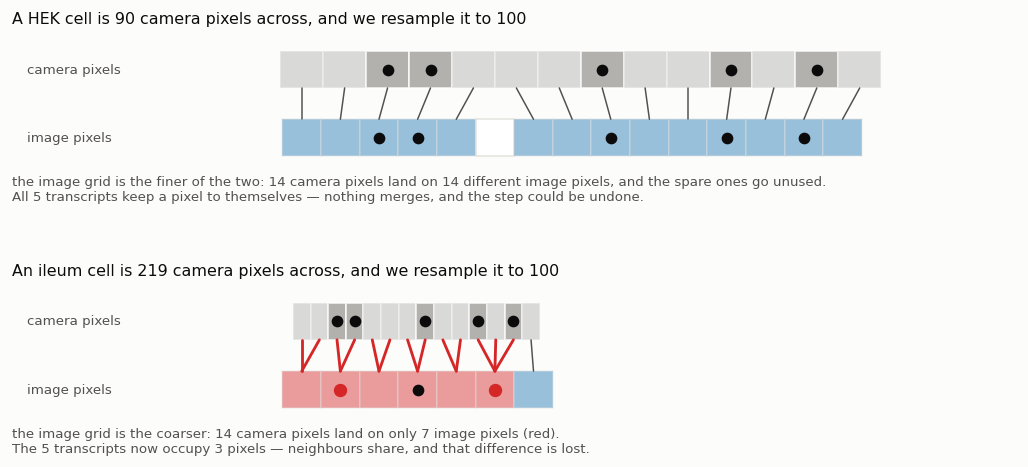

In [2]:
from matplotlib.patches import Rectangle

CAMC, IMGC, HITC = "#9a9894", "#1f77b4", "#d62728"
N_SHOW, SPOTS = 14, (2, 3, 7, 10, 12)      # camera pixels that carry a transcript


def example_cell(ds, want_h, want_w, tol=6):
    """A real cell of about the requested native size, and its bounding box."""
    c = DS[ds]["cells"]
    m = c[(c.bbox_h.sub(want_h).abs() < tol) & (c.bbox_w.sub(want_w).abs() < tol)]
    return m.iloc[len(m) // 2]


def ruler(ax, extent, title, note, xlim):
    """One row of camera pixels, one row of image pixels, and where each one lands."""
    z = GRID / extent                       # image pixels per camera pixel
    k = np.arange(N_SHOW)
    dest = np.rint(k * z).astype(int)
    n_at = {g: int((dest == g).sum()) for g in np.unique(dest)}
    s_at = {g: int((dest[list(SPOTS)] == g).sum()) for g in np.unique(dest[list(SPOTS)])}
    for i in k:
        occ = i in SPOTS
        ax.add_patch(Rectangle((i * z - z/2, .60), z, .27, facecolor=CAMC,
                               alpha=.75 if occ else .35, edgecolor="white", lw=1.1))
        if occ:
            ax.plot(i * z, .735, "o", ms=6, color=INK, zorder=5)
    for g in range(int(dest.max()) + 1):
        used = g in n_at; lost = n_at.get(g, 0) > 1
        ax.add_patch(Rectangle((g - .5, .10), 1, .27,
                               facecolor=HITC if lost else IMGC if used else "#ffffff",
                               alpha=.45 if used else 1.0, edgecolor=GRIDC, lw=.9))
        if g in s_at:
            ax.plot(g, .235, "o", ms=7 if s_at[g] > 1 else 6,
                    color=HITC if s_at[g] > 1 else INK, zorder=5)
    for i, d in zip(k, dest):
        merged = n_at[d] > 1
        ax.plot([i * z, d], [.60, .37], color=HITC if merged else INK_MUTED,
                lw=1.7 if merged else .9, zorder=3, solid_capstyle="round")
    ax.text(xlim[0] + .4, .735, "camera pixels", ha="left", va="center", fontsize=8, color=INK_MUTED)
    ax.text(xlim[0] + .4, .235, "image pixels", ha="left", va="center", fontsize=8, color=INK_MUTED)
    ax.set_xlim(*xlim); ax.set_ylim(0, 1.0); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.text(0, -.04, note, transform=ax.transAxes, fontsize=8, color=INK_MUTED, va="top")
    return len(n_at), len(s_at)


def fig_resample():
    a = example_cell("apex", 85, 85); i = example_cell("ileum", 131, 220)
    f, axes = plt.subplots(2, 1, figsize=(10.8, 4.2), gridspec_kw={"hspace": .85})
    XL = (-7.5, 18.5)
    for ax, ext, lbl in ((axes[0], a.bbox_h, "A HEK cell"),
                         (axes[1], i.bbox_w, "An ileum cell")):
        k = np.arange(N_SHOW); d = np.rint(k * GRID / ext).astype(int)
        nd, ns = len(np.unique(d)), len(np.unique(d[list(SPOTS)]))
        if ext <= GRID:
            note = (f"the image grid is the finer of the two: {N_SHOW} camera pixels land on "
                    f"{nd} different image pixels, and the spare ones go unused.\n"
                    f"All {len(SPOTS)} transcripts keep a pixel to themselves \u2014 nothing merges, "
                    "and the step could be undone.")
        else:
            note = (f"the image grid is the coarser: {N_SHOW} camera pixels land on only {nd} "
                    f"image pixels (red).\n"
                    f"The {len(SPOTS)} transcripts now occupy {ns} pixels \u2014 neighbours share, "
                    "and that difference is lost.")
        ruler(ax, ext, f"{lbl} is {int(ext)} camera pixels across, and we resample it to 100",
              note, XL)
    f.savefig(FIG / "fig0_resample.png", dpi=200, bbox_inches="tight")
    return f

fig_resample();

## 1. How large is a cell, and what does the refit to 100x100 discard?

Transcripts are first placed on an integer grid the size of the cell itself — its
segmentation bounding box — and that grid is then refit to 100x100. So the question is how
the box compares with 100, and the answer is exact rather than approximate: the refit sends
native position `k` to `rint(k x 100 / extent)`, which is **injective whenever the extent is
at most 100 px**. Every native position then lands on a grid pixel of its own and the refit
is invertible; above 100 px the fraction of positions that collapse is exactly
`1 - 100/extent`.

Note the box is much larger than the cell's own area implies — a HEK cell fills only 38 % of
it, so `sqrt(area)` gives 53 px where the box is 85 px. The box is what gets resized, so the
box is the number that matters.

            dataset      n  sqrt_area  major_axis   bbox_h   bbox_w  bbox_fill  frac_axis_over_100  um_per_grid_px_h  um_per_grid_px_w  um_per_native_px  frac_grid_finer  frac_refit_lossless  median_loss_h  median_loss_w  p95_loss
APEX / HEK (Xenium) 154296    52.6498     70.8105  85.0000  85.0000     0.3756              0.4343            0.1806            0.1806            0.2125           0.5494               0.5657         0.0000         0.0000    0.3548
    ileum (MERFISH)    408    71.6798    117.4399 131.0000 220.0000     0.1947              1.0000            0.1415            0.2376            0.1080           0.0000               0.0000         0.2366         0.5409    0.6469


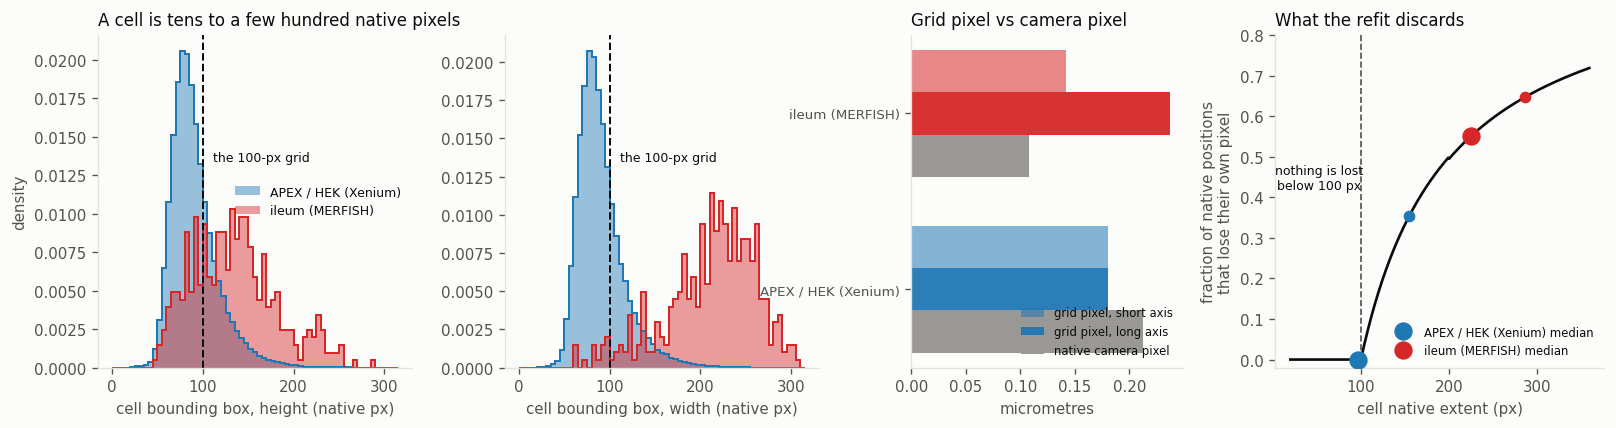

In [3]:
def collapse(extent, grid=GRID):
    """Fraction of native positions that lose their own grid pixel in the refit.

    Exactly 0 while `extent <= grid`, because k -> rint(k*grid/extent) is then injective,
    and `1 - grid/extent` thereafter. Computed rather than asserted.
    """
    k = np.arange(int(extent))
    return 1.0 - len(np.unique(np.rint(k * grid / extent).astype(int))) / extent


for v in DS.values():
    c = v["cells"]
    uniq = {int(x): collapse(int(x)) for x in pd.unique(pd.concat([c.bbox_h, c.bbox_w]))}
    c["loss_h"] = c.bbox_h.astype(int).map(uniq)
    c["loss_w"] = c.bbox_w.astype(int).map(uniq)
    c["lossless"] = (c.loss_h == 0) & (c.loss_w == 0)

rows = []
for k, v in DS.items():
    c = v["cells"]
    mx = c[["bbox_h", "bbox_w"]].max(1)
    rows.append(dict(dataset=v["label"], n=len(c),
                     sqrt_area=np.sqrt(c.Area).median(),
                     major_axis=c.MajorAxisLength.median(),
                     bbox_h=c.bbox_h.median(), bbox_w=c.bbox_w.median(),
                     bbox_fill=(c.Area / (c.bbox_h * c.bbox_w)).median(),
                     frac_axis_over_100=(mx > GRID).mean(),
                     um_per_grid_px_h=(c.bbox_h * v["um_px"] / GRID).median(),
                     um_per_grid_px_w=(c.bbox_w * v["um_px"] / GRID).median(),
                     um_per_native_px=v["um_px"],
                     frac_grid_finer=(np.maximum(c.bbox_h, c.bbox_w) * v["um_px"] / GRID
                                      < v["um_px"]).mean(),
                     frac_refit_lossless=c.lossless.mean(),
                     median_loss_h=c.loss_h.median(), median_loss_w=c.loss_w.median(),
                     p95_loss=np.percentile(c[["loss_h", "loss_w"]].max(1), 95)))
S1 = pd.DataFrame(rows)
print(S1.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


def fig_cellsize():
    f, axes = plt.subplots(1, 4, figsize=(16.2, 3.6),
                           gridspec_kw={"width_ratios": [1.1, 1.1, .95, 1.15], "wspace": 0.30})
    for ax, key in zip(axes[:2], ("bbox_h", "bbox_w")):
        for k, v in DS.items():
            ax.hist(v["cells"][key], bins=np.arange(0, 320, 5), density=True,
                    histtype="stepfilled", alpha=.45, color=v["colour"], label=v["label"])
            ax.hist(v["cells"][key], bins=np.arange(0, 320, 5), density=True,
                    histtype="step", color=v["colour"], lw=1.2)
        ax.axvline(GRID, color=INK, ls="--", lw=1.2)
        ax.annotate("the 100-px grid", (GRID, ax.get_ylim()[1] * .62), xytext=(6, 0),
                    textcoords="offset points", fontsize=7.5, color=INK)
        ax.set_xlabel(f"cell bounding box, {'height' if key=='bbox_h' else 'width'} (native px)")
        ax.set_ylabel("density" if key == "bbox_h" else None)
    axes[0].legend(fontsize=7.5, loc="center right")
    axes[0].set_title("A cell is tens to a few hundred native pixels", loc="left")
    ax = axes[2]
    # both axes separately: the resize is per-axis, so an elongated cell gets a coarse
    # grid pixel along its long dimension and a fine one across it
    y = np.arange(len(DS)) * 1.0; h = 0.24
    for j, (k, v) in enumerate(DS.items()):
        c = v["cells"]
        gh = (c.bbox_h * v["um_px"] / GRID).median()
        gw = (c.bbox_w * v["um_px"] / GRID).median()
        ax.barh(y[j] + h, gh, height=h, color=v["colour"], alpha=.55,
                label="grid pixel, short axis" if j == 0 else None)
        ax.barh(y[j], gw, height=h, color=v["colour"], alpha=.95,
                label="grid pixel, long axis" if j == 0 else None)
        ax.barh(y[j] - h, v["um_px"], height=h, color="#9a9894",
                label="native camera pixel" if j == 0 else None)
    ax.set_yticks(y); ax.set_yticklabels([v["label"] for v in DS.values()], fontsize=8)
    ax.set_xlabel("micrometres"); ax.legend(fontsize=7, loc="lower right")
    ax.set_title("Grid pixel vs camera pixel", loc="left")
    ax = axes[3]
    ext = np.arange(20, 360)
    ax.plot(ext, [collapse(e) for e in ext], color=INK, lw=1.6, zorder=2)
    ax.axvline(GRID, color=INK_MUTED, ls="--", lw=1)
    ax.annotate("nothing is lost\nbelow 100 px", (52, .42), fontsize=7.5, color=INK, ha="center")
    for k, v in DS.items():
        c = v["cells"]
        for q, ms in ((.5, 10), (.95, 6)):
            e = np.maximum(c.bbox_h, c.bbox_w).quantile(q)
            ax.plot([e], [collapse(int(e))], "o", ms=ms, color=v["colour"], zorder=3,
                    label=f"{v['label']} median" if q == .5 else None)
    ax.set_xlabel("cell native extent (px)")
    ax.set_ylabel("fraction of native positions\nthat lose their own pixel")
    ax.set_ylim(-0.02, .8); ax.legend(fontsize=7, loc="lower right")
    ax.set_title("What the refit discards", loc="left")
    f.savefig(FIG / "fig1_cell_size.png", dpi=200, bbox_inches="tight")
    return f

fig_cellsize();

So for most HEK cells the refit discards nothing whatsoever — 57 % are lossless on
both axes, and the median cell loses no positions on either. The two resolutions are also
comparable there, with the grid slightly the finer of the two.

The ileum is the other regime. Every cell exceeds 100 px, the grid pixel is up to twice the
native one on the long axis, and about a quarter of native positions across the cell and half
along it lose their own pixel. That is a real loss and worth stating plainly rather than
averaging away; §2 and §3 ask whether it has consequences for actual transcripts.

## 2. What the refit costs actual transcripts

Two quantisations happen in sequence: `round(local_row)` puts a transcript on the native
camera pixel, then `rint(. x 100/bbox)` puts it on ours. Measuring both on the same scale
shows which dominates.

One caveat on reading the first two panels. A displacement is not by itself a loss of
information: where the refit is injective (§1) it merely rescales, and two transcripts that
were distinguishable stay distinguishable. The displacement bounds how far a transcript can
be from where it belongs.

What bounds the *loss* is the third panel, and it is the number to take away from this
section: **how many transcripts actually end up sharing a pixel with another one**. §1
counted lattice positions, which is the worst case if every position were occupied. The
transcripts are what is really there.

dataset source         n  med_px  p90_px  p99_px  max_px  med_um  p90_um  p99_um  max_um
   apex  cam_r 321668970  0.2505  0.4555  0.5005  0.5005  0.0532  0.0968  0.1064  0.1064
   apex  cam_c 321668970  0.2505  0.4555  0.5005  0.5005  0.0532  0.0968  0.1064  0.1064
   apex grid_r 321668970  0.2195  0.4405  0.6805  1.4995  0.0466  0.0936  0.1446  0.3186
   apex grid_c 321668970  0.2195  0.4405  0.6805  1.4995  0.0466  0.0936  0.1446  0.3186

APEX / HEK (Xenium)    modelled observations  82,025 | conflict-free observations 0.9556 | TRANSCRIPTS SHARING A PIXEL 0.0043 | grid filled 0.0018
ileum (MERFISH)        modelled observations   3,358 | conflict-free observations 0.8993 | TRANSCRIPTS SHARING A PIXEL 0.0113 | grid filled 0.0017


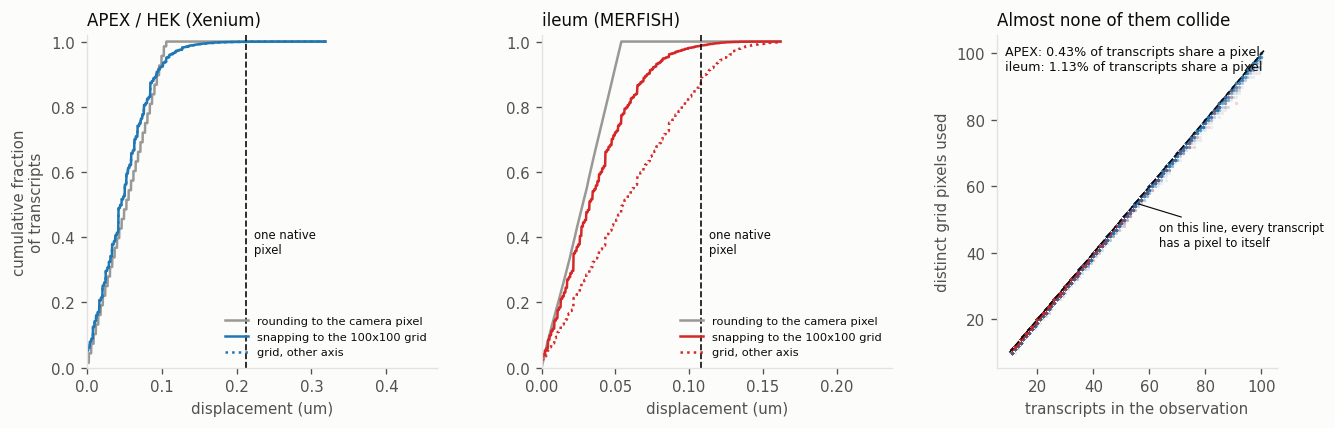

In [4]:
BINS = np.linspace(0, 1.5, 1501)
MID = (BINS[:-1] + BINS[1:]) / 2
print(DS["apex"]["disp"].to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
CONFLICT = {}
for k, v in DS.items():
    o = v["occ"]; m = o[(o.n_spots > 10) & (o.n_spots < 101)]
    CONFLICT[k] = dict(obs=len(m),
                       conflict_free=(m.n_conflicted == 0).mean(),
                       transcripts=m.n_conflicted.sum() / m.n_spots.sum(),
                       filled=m.n_spots.median() / GRID**2)
    c = CONFLICT[k]
    print(f"{v['label']:22s} modelled observations {c['obs']:>7,} | "
          f"conflict-free observations {c['conflict_free']:.4f} | "
          f"TRANSCRIPTS SHARING A PIXEL {c['transcripts']:.4f} | "
          f"grid filled {c['filled']:.4f}")


def fig_cost():
    f, axes = plt.subplots(1, 3, figsize=(12.8, 3.6),
                           gridspec_kw={"width_ratios": [1.25, 1.25, 1], "wspace": 0.32})
    for ax, k in zip(axes[:2], DS):
        v = DS[k]; u = v["um_px"]
        for src, lbl, c, ls in (("cam_r", "rounding to the camera pixel", "#9a9894", "-"),
                                ("grid_r", "snapping to the 100x100 grid", v["colour"], "-"),
                                ("grid_c", "grid, other axis", v["colour"], ":")):
            h = v["hist"][src].astype(float); h /= h.sum()
            ax.plot(MID * u, np.cumsum(h), color=c, lw=1.5, ls=ls, label=lbl)
        ax.axvline(u, color=INK, ls="--", lw=1)
        ax.annotate("one native\npixel", (u, .35), xytext=(5, 0), textcoords="offset points",
                    fontsize=7, color=INK)
        ax.set_xlim(0, u * 2.2); ax.set_ylim(0, 1.02)
        ax.set_xlabel("displacement (um)"); ax.set_title(v["label"], loc="left")
        if k == "apex":
            ax.set_ylabel("cumulative fraction\nof transcripts")
        ax.legend(fontsize=6.8, loc="lower right")
    ax = axes[2]
    for k, v in DS.items():
        o = v["occ"]; m = o[(o.n_spots > 10) & (o.n_spots < 101)]
        ax.scatter(m.n_spots, m.n_pixels, s=4, alpha=.10, color=v["colour"],
                   linewidths=0, rasterized=True, label=v["label"])
    lim = [10, 101]
    ax.plot(lim, lim, color=INK, lw=1, ls="--")
    ax.annotate("on this line, every transcript\nhas a pixel to itself", (55, 55),
                xytext=(14, -26), textcoords="offset points", fontsize=7, color=INK,
                ha="left", arrowprops=dict(arrowstyle="-", color=INK, lw=.7))
    txt = "\n".join(f"{DS[k]['label'].split(' /')[0].split(' (')[0]}: "
                     f"{CONFLICT[k]['transcripts']:.2%} of transcripts share a pixel"
                     for k in DS)
    ax.text(.03, .97, txt, transform=ax.transAxes, va="top", fontsize=7.6, color=INK)
    ax.set_xlabel("transcripts in the observation"); ax.set_ylabel("distinct grid pixels used")
    ax.set_title("Almost none of them collide", loc="left")
    f.savefig(FIG / "fig2_cost.png", dpi=200, bbox_inches="tight")
    return f

fig_cost();

**In the HEK data a collision is essentially a non-event: 0.4 % of transcripts
share a pixel with another, and 95.6 % of observations have none at all.** That follows from
§1 — for most of those cells the refit discards nothing to begin with.

**And where the refit genuinely does discard lattice positions, it still barely matters.**
The ileum loses about half of its native positions along the long axis of a cell, which
sounds severe, yet only **1.1 %** of its transcripts end up sharing a pixel, and 90 % of
observations remain entirely conflict-free. The reason is the third panel: an observation
puts a few tens of transcripts into 10,000 pixels, so the grid is about 99.8 % empty. Losing
half of a lattice that was almost entirely unoccupied costs almost nothing, because the
positions that disappear were overwhelmingly empty ones.

So the two datasets bracket the question. In the current-generation data the resampling is
lossless for most cells and conflicts are negligible; in the older, coarser-sampled data the
resampling does lose lattice positions, and the practical cost is still around one transcript
in a hundred.

On displacement: the refit contributes less than the camera rounding that precedes it on the
HEK data, and about twice as much on the ileum's compressed axis — but in absolute terms
every one of these numbers is well under a fifth of a micrometre.

## 3. Could a one-pixel error change the compartment?

How far is a
transcript from the nuclear boundary, how many are close enough that one pixel would matter,
and how large is the error we actually make on the same scale. The flip rate is the union
over a one-pixel shift in each of the four directions, so it is an upper bound rather than
a typical case.

            dataset  transcripts  median_dist_px  median_dist_um  frac_within_1px  flip_rate_1px  actual_disp_px  ratio  inside_nucleus
APEX / HEK (Xenium)      5207366          9.0000          1.6256           0.0666         0.0666          0.2582 3.8724          0.6639
    ileum (MERFISH)       179286          9.4340          1.3347           0.0575         0.0575          0.2294 4.3594          0.3760


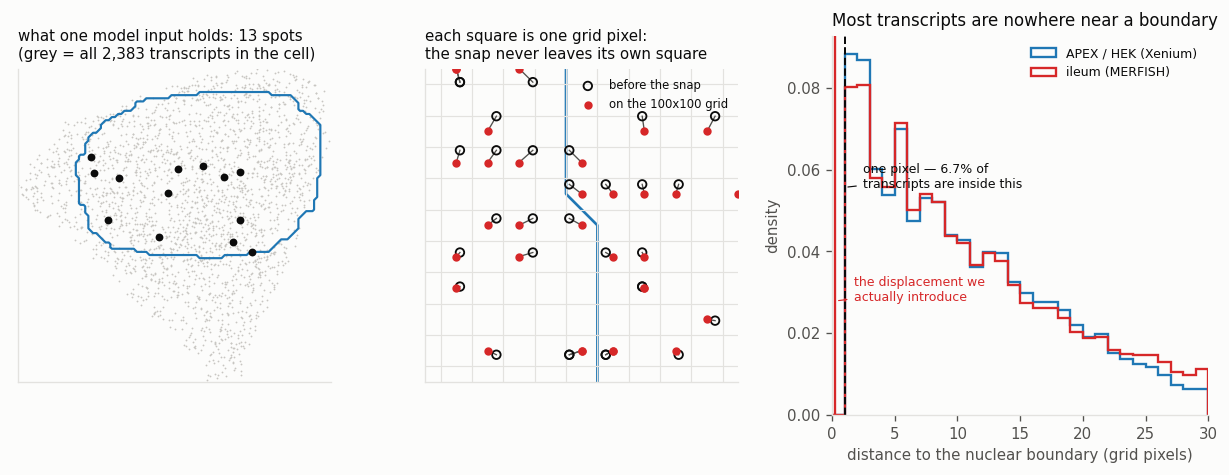

In [5]:
rows = []
for k, v in DS.items():
    b = v["bnd"]; gpx = (v["cells"].bbox_h * v["um_px"] / GRID).median()
    med_disp_px = v["disp"].query("source == 'grid_r'").med_px.iloc[0] * (GRID / v["cells"].bbox_h.median())
    rows.append(dict(dataset=v["label"], transcripts=len(b),
                     median_dist_px=b.dist.median(), median_dist_um=b.dist.median() * gpx,
                     frac_within_1px=(b.dist <= 1).mean(), flip_rate_1px=b.flip.mean(),
                     actual_disp_px=med_disp_px,
                     ratio=1.0 / med_disp_px, inside_nucleus=b.inside.mean()))
S3 = pd.DataFrame(rows)
print(S3.to_string(index=False, float_format=lambda v: f"{v:.4f}"))


def fig_boundary():
    """Panel b is the point: the move the grid makes, against the move being worried about."""
    k = "apex"; v = DS[k]
    # one mid-sized cell and one gene in it, cut out of the published APEX-seq object by
    # scripts/input_resolution/extract_example_cell.py
    ex = np.load(WORK / "example_cell_apex.npz")
    b0, b1, h, w = (float(ex[x]) for x in ("b0", "b1", "h", "w"))
    lr, lc = ex["local_row"], ex["local_col"]
    sr, sc = ex["subcell_row"], ex["subcell_col"]
    mask, gsel = ex["dapi_mask"], ex["gene_selected"]
    # Two quantisations, and this panel is about the second one only. `pre` is the
    # position after the camera rounding that the pipeline applies first; `sr/sc` is
    # after the snap to our grid. Showing the truly exact micron position instead would
    # mix in the camera term, which is the larger of the two (see section 2).
    pre_r = (np.round(lr) - b0) * (GRID / h); pre_c = (np.round(lc) - b1) * (GRID / w)
    exact_r = (lr - b0) * (GRID / h); exact_c = (lc - b1) * (GRID / w)

    f2, axes = plt.subplots(1, 3, figsize=(12.8, 4.1),
                            gridspec_kw={"width_ratios": [1, 1, 1.2], "wspace": 0.28})
    ax = axes[0]
    ax.contour(mask, levels=[.5], colors=["#1f77b4"], linewidths=1.3)
    ax.scatter(exact_c, exact_r, s=1.2, color="#c8c6c2", linewidths=0, rasterized=True)
    ax.scatter(exact_c[gsel], exact_r[gsel], s=22, color=INK, linewidths=0, zorder=3)
    ax.set_aspect("equal")
    ax.set_title(f"what one model input holds: {gsel.sum()} spots\n"
                 f"(grey = all {len(lr):,} transcripts in the cell)", loc="left", fontsize=9)
    ax.set_xlim(0, GRID); ax.set_ylim(GRID, 0); ax.set_xticks([]); ax.set_yticks([])
    # zoom on a patch straddling the nuclear boundary
    edge = np.argwhere(mask ^ np.roll(mask, 1, 0))
    cr, cc = edge[len(edge) // 2]
    R = 5
    ax = axes[1]
    sel = (np.abs(exact_r - cr) < R) & (np.abs(exact_c - cc) < R)
    ax.contour(mask, levels=[.5], colors=["#1f77b4"], linewidths=1.6)
    for g in range(int(cc - R), int(cc + R) + 1):
        ax.axvline(g - .5, color=GRIDC, lw=.7)
    for g in range(int(cr - R), int(cr + R) + 1):
        ax.axhline(g - .5, color=GRIDC, lw=.7)
    ax.scatter(pre_c[sel], pre_r[sel], s=26, facecolor="none", edgecolor=INK,
               lw=1.1, label="before the snap", zorder=3)
    ax.scatter(sc[sel], sr[sel], s=16, color="#d62728", label="on the 100x100 grid", zorder=4)
    for a, b_, c_, d_ in zip(pre_c[sel], pre_r[sel], sc[sel], sr[sel]):
        ax.plot([a, c_], [b_, d_], color=INK_MUTED, lw=.8, zorder=2)
    ax.set_aspect("equal")
    ax.set_xlim(cc - R, cc + R); ax.set_ylim(cr + R, cr - R)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("each square is one grid pixel:\nthe snap never leaves its own square",
                 loc="left", fontsize=9)
    ax.legend(fontsize=7, loc="upper right")
    ax = axes[2]
    for k2, v2 in DS.items():
        b = v2["bnd"]
        ax.hist(b.dist, bins=np.arange(0, 31, 1), density=True, histtype="step",
                color=v2["colour"], lw=1.4, label=v2["label"])
    ax.set_xlim(0, 30)                     # tail continues; not clipped into the last bin
    top = ax.get_ylim()[1]
    ax.axvline(1, color=INK, ls="--", lw=1.2)
    ax.axvline(S3.actual_disp_px.iloc[0], color="#d62728", lw=1.4)
    ax.annotate(f"one pixel — {S3.frac_within_1px.iloc[0]:.1%} of\ntranscripts are inside this",
                (1, top * .60), xytext=(11, 0), textcoords="offset points",
                fontsize=7.5, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK, lw=.7))
    ax.annotate("the displacement we\nactually introduce",
                (S3.actual_disp_px.iloc[0], top * .30), xytext=(11, 0),
                textcoords="offset points", fontsize=7.5, color="#d62728",
                arrowprops=dict(arrowstyle="-", color="#d62728", lw=.7))
    ax.set_xlabel("distance to the nuclear boundary (grid pixels)")
    ax.set_ylabel("density"); ax.legend(fontsize=7.5)
    ax.set_title("Most transcripts are nowhere near a boundary", loc="left")
    f2.savefig(FIG / "fig3_boundary.png", dpi=200, bbox_inches="tight")
    return f2

fig_boundary();

## In short

The 100x100 frame is not where spatial precision is lost. Refitting a cell's own native
grid onto 100x100 is exactly lossless while the cell spans no more than 100 pixels, which
covers 57 % of HEK cells and the median cell on both axes; one grid pixel is then 0.18 um
against a 0.2125 um camera pixel, and the refit displaces a transcript less than the
rounding onto camera pixels that precedes it. Only **0.4 %** of HEK transcripts share a
pixel with another. Even in the older, more coarsely sampled ileum data, where the refit
does collapse about half the native positions along a cell's long axis, the cost is
**1.1 %** of transcripts — the frame is ~99.8 % empty, so the positions lost are almost all
empty ones. Boundary crossing is a real mechanism but a small one: most transcripts sit some
1.6 um from the nuclear boundary, only 6.7 % are within one pixel of it, and the
displacement the grid introduces is about a quarter of a pixel.

Elongated cells are a larger issue. Because the crop is resized
per-axis, a long cell has its long axis compressed — every ileum cell exceeds 100 px, and
there one grid pixel is about twice the native pixel. This is a limitation, and it argues for a larger frame if the method were applied to markedly larger
or more elongated cells than the ones here.